
# Sri Lanka Food Price Predictor

## 1. Data Loading, Inspection and Cleaning

### Project Overview

This project aims to predict food prices in Sri Lanka using Ensemble Learning techniques.

The dataset is obtained from the World Food Programme (WFP) through the Humanitarian Data Exchange (HDX).

**Dataset:** WFP Food Prices for Sri Lanka

**Dataset Source:** https://data.humdata.org/dataset/wfp-food-prices-for-sri-lanka

**Target Variable:** price (LKR)


In [40]:
# Import required libraries
import numpy as np
import pandas as pd

# Load dataset
df = pd.read_csv("../data/wfp_food_prices_lka.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [41]:

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names and data types
df.info()

# Display first five records
display(df.head())


Dataset Shape: (34262, 16)
<class 'pandas.DataFrame'>
RangeIndex: 34262 entries, 0 to 34261
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          34262 non-null  str    
 1   admin1        34068 non-null  str    
 2   admin2        34068 non-null  str    
 3   market        34262 non-null  str    
 4   market_id     34262 non-null  int64  
 5   latitude      34068 non-null  float64
 6   longitude     34068 non-null  float64
 7   category      34262 non-null  str    
 8   commodity     34262 non-null  str    
 9   commodity_id  34262 non-null  int64  
 10  unit          34262 non-null  str    
 11  priceflag     34262 non-null  str    
 12  pricetype     34262 non-null  str    
 13  currency      34262 non-null  str    
 14  price         34262 non-null  float64
 15  usdprice      34262 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 7.0 MB


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.71,0.33
1,2004-01-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.66,0.27
2,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,33.62,0.34
3,2004-02-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Wheat flour,58,KG,actual,Retail,LKR,26.71,0.27
4,2004-03-15,Western,Colombo,Colombo City,368,6.93,79.85,cereals and tubers,Rice (red nadu),157,KG,actual,Retail,LKR,32.92,0.34



### 1.2 Data Quality Analysis

Analyze the dataset's data types, missing values and duplicate records to identify potential data quality issues before cleaning.


In [42]:

# Check data types and missing values

quality_report = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

display(quality_report)


,Data Type,Missing Values,Missing Percentage
date,str,0,0.000000
admin1,str,194,0.566225
admin2,str,194,0.566225
market,str,0,0.000000
market_id,int64,0,0.000000
latitude,float64,194,0.566225
longitude,float64,194,0.566225
category,str,0,0.000000
commodity,str,0,0.000000
commodity_id,int64,0,0.000000


In [43]:

# Check duplicate records

print("Duplicate records:", df.duplicated().sum())


Duplicate records: 0



### 1.3 Statistical Analysis

Examine numerical features to understand their distributions, ranges and potential unusual values. Special attention is given to the target variable, price.


In [44]:

# Statistical summary of numerical columns

display(df.describe())

# Food price distribution
display(df['price'].describe())


,market_id,latitude,longitude,commodity_id,price,usdprice
count,34262.000000,34068.000000,34068.00000,34262.000000,34262.000000,34262.000000
mean,3058.342274,7.465483,80.58758,408.069027,610.759387,2.051197
std,2803.731369,0.938003,0.52563,266.190555,631.260915,2.033672
min,360.000000,5.950000,79.83000,50.000000,11.500000,0.060000
25%,368.000000,6.870000,80.12000,133.000000,183.000000,0.680000
50%,1912.000000,7.250000,80.52000,408.000000,337.500000,1.110000
75%,5346.000000,8.040000,81.01000,679.000000,883.330000,2.940000
max,7843.000000,9.660000,81.70000,1037.000000,3735.420000,11.950000


count    34262.000000
mean       610.759387
std        631.260915
min         11.500000
25%        183.000000
50%        337.500000
75%        883.330000
max       3735.420000
Name: price, dtype: float64


### 1.4 Data Cleaning

Clean the dataset by converting date values into the appropriate format and investigating missing geographical information and invalid price observations.

Valid food-price records will be preserved throughout the cleaning process.


In [45]:

# Create a working copy
cleaned_data = df.copy()

print("Working dataset created:", cleaned_data.shape)


Working dataset created: (34262, 16)


In [46]:

# Convert date column to datetime
cleaned_data['date'] = pd.to_datetime(
    cleaned_data['date'],
    errors='coerce'
)

print("Date data type:", cleaned_data['date'].dtype)
print("Invalid dates:", cleaned_data['date'].isna().sum())

print("Date range:",
      cleaned_data['date'].min(),
      "to",
      cleaned_data['date'].max())


Date data type: datetime64[us]
Invalid dates: 0
Date range: 2004-01-15 00:00:00 to 2025-09-15 00:00:00


In [47]:

# Identify records with missing geographical information

missing_location = cleaned_data[
    cleaned_data['admin1'].isna()
]

print("Records with missing location:", len(missing_location))

display(
    missing_location[
        ['market', 'admin1', 'admin2', 'latitude', 'longitude']
    ].drop_duplicates()
)


Records with missing location: 194


,market,admin1,admin2,latitude,longitude
616,National Average,NaN,NaN,NaN,NaN


In [48]:

# Check currency distribution
print("Currency distribution:")
print(cleaned_data['currency'].value_counts())

# Check invalid prices
print("\nNegative prices:",
      (cleaned_data['price'] < 0).sum())

print("Zero prices:",
      (cleaned_data['price'] == 0).sum())

print("Missing prices:",
      cleaned_data['price'].isna().sum())


Currency distribution:
currency
LKR    34262
Name: count, dtype: int64

Negative prices: 0
Zero prices: 0
Missing prices: 0


### 1.4 Data Cleaning

The dataset contains no invalid dates, missing prices, zero prices or negative prices.

The 194 records with missing geographical information belong to the National Average market. These records are retained because they represent valid national-level price observations.

The date column has been converted to datetime format.

In [49]:
# Preserve all valid observations
cleaned_data = cleaned_data.dropna(subset=['date', 'price'])

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", cleaned_data.shape)

Original dataset shape: (34262, 16)
Cleaned dataset shape: (34262, 16)


## 2. Exploratory Data Analysis (EDA)

EDA is performed to understand the distribution of food prices and identify important patterns and relationships within the dataset.

### 2.1 Target Variable Analysis

Analyze the distribution and statistical characteristics of the target variable, price.

In [50]:
display(cleaned_data['price'].describe())

count    34262.000000
mean       610.759387
std        631.260915
min         11.500000
25%        183.000000
50%        337.500000
75%        883.330000
max       3735.420000
Name: price, dtype: float64

In [51]:
print("Number of unique commodities:", cleaned_data['commodity'].nunique())
print("Number of unique markets:", cleaned_data['market'].nunique())
print("Number of unique units:", cleaned_data['unit'].nunique())
print("Number of price types:", cleaned_data['pricetype'].nunique())

Number of unique commodities: 42
Number of unique markets: 44
Number of unique units: 4
Number of price types: 2


In [52]:
print("Price type distribution:")
display(cleaned_data['pricetype'].value_counts())

print("Measurement unit distribution:")
display(cleaned_data['unit'].value_counts())

Price type distribution:


pricetype
Retail       33627
Wholesale      635
Name: count, dtype: int64

Measurement unit distribution:


unit
KG        31705
Unit       1994
L           543
750 ML       20
Name: count, dtype: int64

### 2.2 Price Distribution

A histogram is used to examine the distribution of food prices and identify skewness and potential extreme observations.

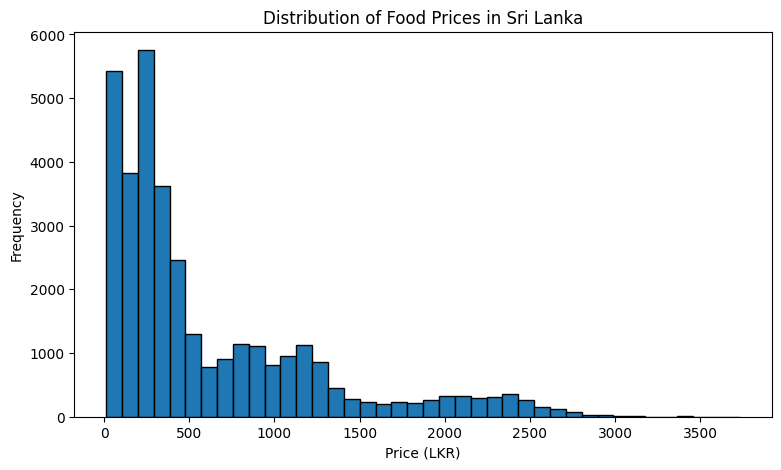

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(cleaned_data['price'], bins=40, edgecolor='black')
plt.title('Distribution of Food Prices in Sri Lanka')
plt.xlabel('Price (LKR)')
plt.ylabel('Frequency')
plt.show()

### 2.3 Food Price Trends Over Time

Analyze the average recorded food price over time to identify long-term trends and changes in food prices in Sri Lanka.

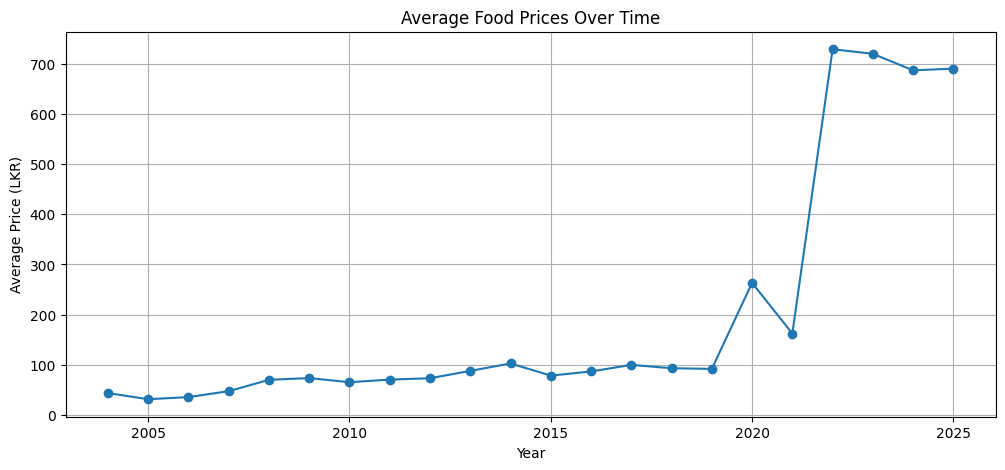

In [54]:
yearly_prices = (
    cleaned_data.groupby(cleaned_data['date'].dt.year)['price']
    .mean()
)

plt.figure(figsize=(12, 5))
plt.plot(yearly_prices.index, yearly_prices.values, marker='o')
plt.title('Average Food Prices Over Time')
plt.xlabel('Year')
plt.ylabel('Average Price (LKR)')
plt.grid(True)
plt.show()

### 2.4 Average Price by Commodity

Compare average recorded prices across commodities to understand price differences between food items.

In [55]:
commodity_prices = (
    cleaned_data.groupby('commodity')['price']
    .mean()
    .sort_values(ascending=False)
)

display(commodity_prices.head(10))

commodity
Fish (sail fish)              2390.298254
Fish (dry, katta)             2163.731192
Fish (yellowfin tuna)         2057.127582
Fish (jack)                   1684.562185
Meat (chicken, broiler)       1248.522764
Fish (skipjack tuna)          1211.197317
Fish (dry, sprats)            1141.454214
Meat (chicken, fresh)         1076.979000
Beans (mung)                   947.018808
Fish (trenched sardinella)     930.854877
Name: price, dtype: float64

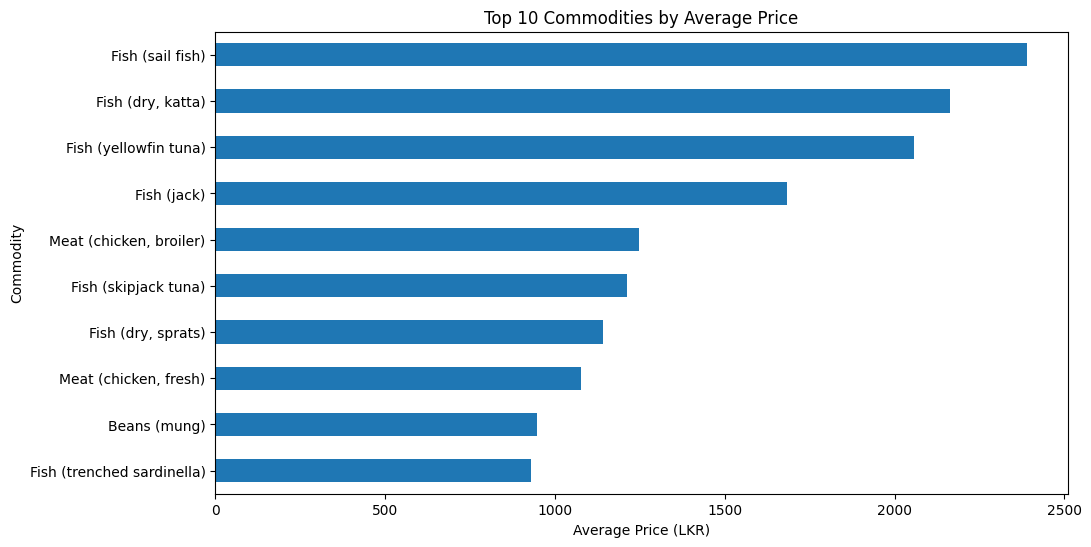

In [56]:
plt.figure(figsize=(11, 6))
commodity_prices.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Commodities by Average Price')
plt.xlabel('Average Price (LKR)')
plt.ylabel('Commodity')
plt.show()

### 2.5 Average Price by Market

Compare average recorded food prices across markets to identify geographical differences in the dataset.

In [57]:
market_prices = (
    cleaned_data.groupby('market')['price']
    .mean()
    .sort_values(ascending=False)
)

display(market_prices.head(10))

market
Fish market-Peliyagoda    1045.841910
Galenbindunuwewa           758.698402
Bandarawela                740.802039
Nikaweratiya               725.680040
Meegoda(DEC)               721.403891
Embilipitiya               705.954574
Keppetipola (DEC}          694.545948
Kegalle                    691.096711
Galle                      690.186608
Kalutara                   680.964919
Name: price, dtype: float64

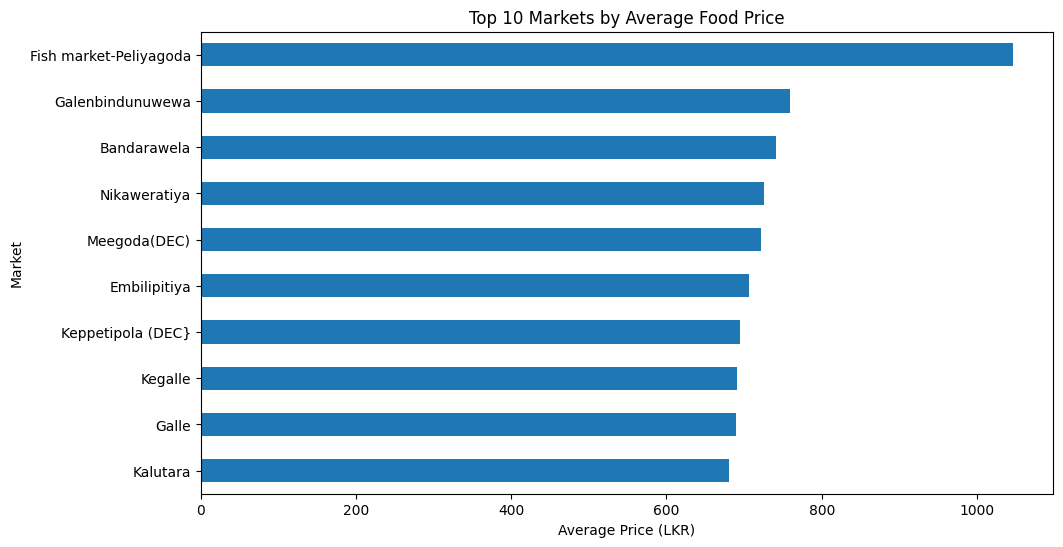

In [58]:
plt.figure(figsize=(11, 6))
market_prices.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Markets by Average Food Price')
plt.xlabel('Average Price (LKR)')
plt.ylabel('Market')
plt.show()

The market analysis reveals geographical variation in average recorded food prices. Fish market-Peliyagoda has the highest average price among the markets. However, differences in commodity composition and measurement units may influence these averages.

### 2.6 Correlation Analysis

Examine the relationships between food prices and geographical coordinates using a correlation matrix.

In [59]:
correlation_data = cleaned_data[
    ['latitude', 'longitude', 'price']
].corr()

display(correlation_data)

,latitude,longitude,price
latitude,1.00000,-0.119190,-0.064250
longitude,-0.11919,1.000000,0.026721
price,-0.06425,0.026721,1.000000


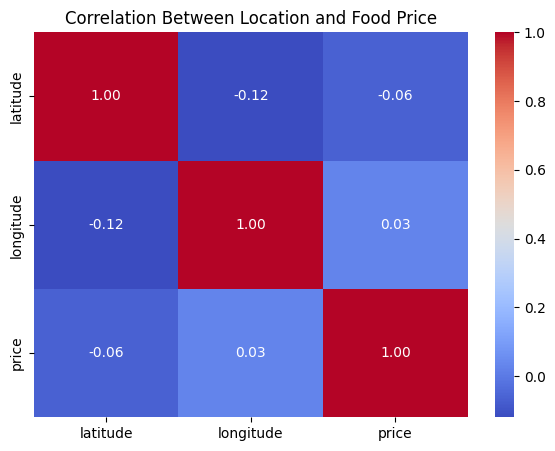

In [60]:
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Between Location and Food Price')
plt.show()

The correlation analysis indicates very weak linear relationships between geographical coordinates and food prices. Latitude has a correlation of -0.06 with price, while longitude has a correlation of 0.03. These features may still provide useful geographical information to machine-learning models through nonlinear relationships.

## 3. Feature Engineering and Data Preprocessing

### 3.1 Date Feature Extraction

Extract meaningful temporal features from the date column to help machine-learning models identify seasonal and long-term food price patterns.

In [61]:
cleaned_data['year'] = cleaned_data['date'].dt.year
cleaned_data['month'] = cleaned_data['date'].dt.month
cleaned_data['quarter'] = cleaned_data['date'].dt.quarter

In [62]:
display(
    cleaned_data[
        ['date', 'year', 'month', 'quarter']
    ].head()
)

,date,year,month,quarter
0,2004-01-15,2004,1,1
1,2004-01-15,2004,1,1
2,2004-02-15,2004,2,1
3,2004-02-15,2004,2,1
4,2004-03-15,2004,3,1


### 3.2 Feature and Target Selection

Select relevant input features for predicting food prices.

The USD price and identifier columns are excluded to avoid target leakage and redundant information.

In [63]:
features = [
    'year',
    'month',
    'quarter',
    'commodity',
    'market',
    'unit',
    'pricetype',
    'latitude',
    'longitude'
]

X = cleaned_data[features]
y = cleaned_data['price']

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
display(X.head())

Feature dataset shape: (34262, 9)
Target dataset shape: (34262,)


,year,month,quarter,commodity,market,unit,pricetype,latitude,longitude
0,2004,1,1,Rice (red nadu),Colombo City,KG,Retail,6.93,79.85
1,2004,1,1,Wheat flour,Colombo City,KG,Retail,6.93,79.85
2,2004,2,1,Rice (red nadu),Colombo City,KG,Retail,6.93,79.85
3,2004,2,1,Wheat flour,Colombo City,KG,Retail,6.93,79.85
4,2004,3,1,Rice (red nadu),Colombo City,KG,Retail,6.93,79.85


### 3.3 Missing Value Analysis

Inspect missing values in the selected input features before preprocessing. National Average records are retained because they represent valid national-level observations.

In [64]:
missing_features = X.isnull().sum()

display(missing_features[missing_features > 0])

latitude     194
longitude    194
dtype: int64

### 3.4 Handling Missing Geographical Values

Create a binary feature to identify National Average observations. Missing geographical coordinates are filled with neutral values while the indicator preserves information about their national-level status.

In [65]:
X['is_national_average'] = (
    X['market'] == 'National Average'
).astype(int)

In [66]:
X[['latitude', 'longitude']] = X[['latitude', 'longitude']].fillna(0)

In [67]:
print(X[['latitude', 'longitude']].isnull().sum())
print("National Average records:", X['is_national_average'].sum())

latitude     0
longitude    0
dtype: int64
National Average records: 194


### 3.5 Categorical Feature Analysis

Inspect the unique values in categorical features before applying encoding techniques.

In [68]:
categorical_features = [
    'commodity',
    'market',
    'unit',
    'pricetype'
]

for column in categorical_features:
    print(f"{column}: {X[column].nunique()} unique values")

commodity: 42 unique values
market: 44 unique values
unit: 4 unique values
pricetype: 2 unique values


### 3.7 Temporal Data Distribution

Examine the number of observations recorded each year before creating chronological training and testing datasets.

In [69]:
yearly_records = cleaned_data.groupby('year').size()

display(yearly_records)

year
2004       51
2005       22
2006      178
2007      211
2008      154
2009      166
2010      191
2011      234
2012      166
2013       78
2014       60
2015      618
2016      662
2017     1090
2018       51
2019       24
2020     1024
2021      125
2022      232
2023     7607
2024    12220
2025     9098
dtype: int64

The dataset has an uneven temporal distribution, with significantly more observations in 2023–2025. A chronological train/test split is selected to evaluate the model on future observations and reduce temporal data leakage.

The training dataset will contain observations from 2004–2024, while 2025 observations will be reserved for testing.

In [70]:
print("Training period records (2004–2024):",
      (cleaned_data['year'] <= 2024).sum())

print("Testing period records (2025):",
      (cleaned_data['year'] == 2025).sum())

Training period records (2004–2024): 25164
Testing period records (2025): 9098


### 3.8 Chronological Train-Test Split

Split the dataset chronologically, using observations from 2004–2024 for training and observations from 2025 for testing.

This approach evaluates the model's ability to predict food prices for a future period.

In [71]:
train_mask = cleaned_data['year'] <= 2024
test_mask = cleaned_data['year'] == 2025

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25164, 10)
X_test: (9098, 10)
y_train: (25164,)
y_test: (9098,)


In [72]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

### 3.10 Feature Grouping

Separate numerical and categorical features so that appropriate preprocessing techniques can be applied to each group.

In [73]:
numerical_features = [
    'year',
    'month',
    'quarter',
    'latitude',
    'longitude',
    'is_national_average'
]

categorical_features = [
    'commodity',
    'market',
    'unit',
    'pricetype'
]

In [74]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Numerical features: 6
Categorical features: 4
Total features: 10


In [75]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [76]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [77]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (25164, 10)
Processed training shape: (25164, 98)

Original testing shape: (9098, 10)
Processed testing shape: (9098, 98)


In [78]:
import numpy as np

print("Training data contains NaN:", np.isnan(X_train_processed.data).any())
print("Testing data contains NaN:", np.isnan(X_test_processed.data).any())

Training data contains NaN: False
Testing data contains NaN: False


## 4. Ensemble Learning Models


### 4.1 Bagging – Random Forest Regression

Random Forest is a bagging-based ensemble learning algorithm that
combines multiple decision trees to produce predictions.

It uses bootstrap sampling to create different training subsets
and random feature selection when constructing decision trees.

For regression tasks, predictions from individual trees are
combined through averaging.

In this project, Random Forest will be used as the baseline
ensemble model for predicting Sri Lankan food prices.

In [79]:
from sklearn.ensemble import RandomForestRegressor

In [80]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

In [81]:
rf_model.fit(X_train_processed, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [82]:
rf_predictions = rf_model.predict(X_test_processed)

In [83]:
print("Number of predictions:", len(rf_predictions))
print("First 10 predictions:", rf_predictions[:10])

Number of predictions: 9098
First 10 predictions: [ 203.6176  440.2249  219.8536  257.2256   52.4752 2205.53   1286.8883
 1029.8522 1644.1031 2267.5531]


In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [85]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

rf_r2 = r2_score(y_test, rf_predictions)

In [86]:
print("Random Forest Performance")
print("--------------------------")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.4f}")

Random Forest Performance
--------------------------
MAE:  134.51
RMSE: 202.19
R²:   0.9041


In [87]:
rf_results = {
    'Model': 'Random Forest',
    'MAE': rf_mae,
    'RMSE': rf_rmse,
    'R2': rf_r2
}

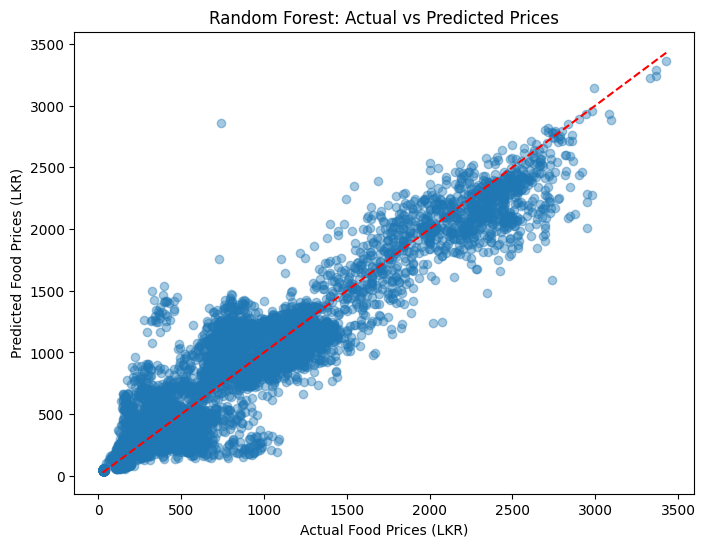

In [88]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Food Prices (LKR)")
plt.ylabel("Predicted Food Prices (LKR)")
plt.title("Random Forest: Actual vs Predicted Prices")

plt.show()

In [89]:
rf_error = y_test - rf_predictions

In [90]:
print("Mean Prediction Error:", rf_error.mean())

Mean Prediction Error: -12.347911958672235


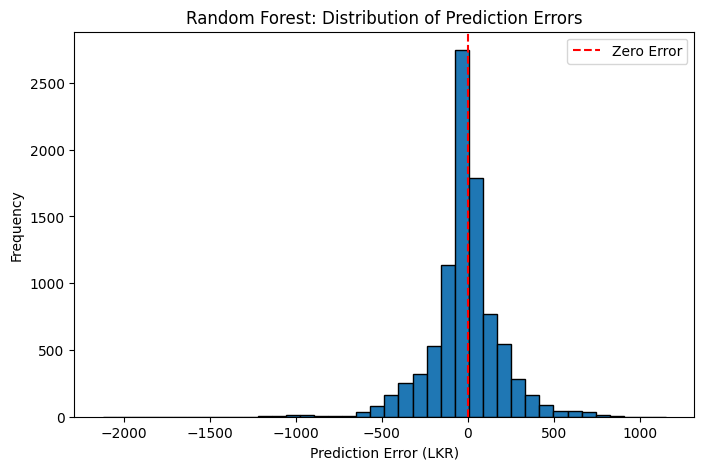

In [91]:
plt.figure(figsize=(8, 5))

plt.hist(rf_error, bins=40, edgecolor='black')

plt.axvline(0, color='red', linestyle='--', label='Zero Error')

plt.xlabel("Prediction Error (LKR)")
plt.ylabel("Frequency")
plt.title("Random Forest: Distribution of Prediction Errors")
plt.legend()

plt.show()

In [92]:
feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(feature_names))
print("First 15 feature names:")
print(feature_names[:15])

Total processed features: 98
First 15 feature names:
['num__year' 'num__month' 'num__quarter' 'num__latitude' 'num__longitude'
 'num__is_national_average' 'cat__commodity_Bananas'
 'cat__commodity_Beans' 'cat__commodity_Beans (mung)'
 'cat__commodity_Cabbage' 'cat__commodity_Carrots'
 'cat__commodity_Chili (red, dry raw)' 'cat__commodity_Coconut'
 'cat__commodity_Cowpeas (whole, average)' 'cat__commodity_Eggplants']


In [93]:
rf_importance = rf_model.feature_importances_

print("Number of importance values:", len(rf_importance))
print("Total importance:", rf_importance.sum())

Number of importance values: 98
Total importance: 1.0


In [94]:
rf_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance
})

In [95]:
rf_importance_df = rf_importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(rf_importance_df.head(15))

,Feature,Importance
20,cat__commodity_Fish (sail fish),0.185757
16,"cat__commodity_Fish (dry, katta)",0.179809
23,cat__commodity_Fish (yellowfin tuna),0.148081
0,num__year,0.097803
19,cat__commodity_Fish (jack),0.094237
27,"cat__commodity_Meat (chicken, broiler)",0.038484
21,cat__commodity_Fish (skipjack tuna),0.036983
17,"cat__commodity_Fish (dry, sprats)",0.036169
11,"cat__commodity_Chili (red, dry raw)",0.027100
8,cat__commodity_Beans (mung),0.026565


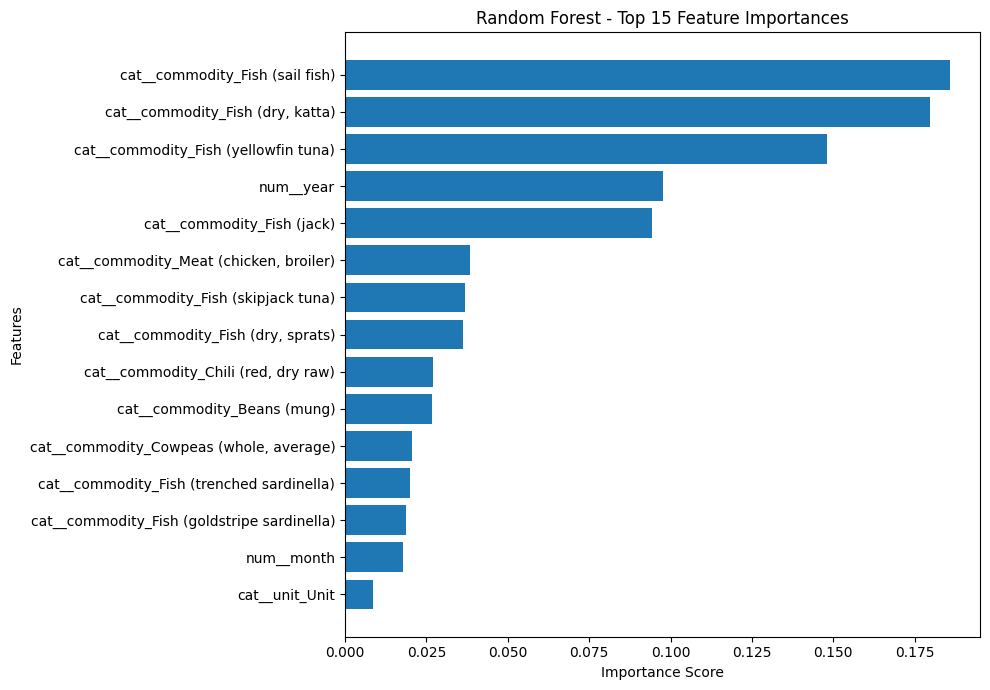

In [96]:
top_features = rf_importance_df.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest - Top 15 Feature Importances")

plt.tight_layout()
plt.show()

### Random Forest – Feature Importance Analysis

The feature importance analysis indicates that commodity-related
features are the most influential factors in predicting food prices.

In [97]:
tune_train_mask = X_train['year'] <= 2023
validation_mask = X_train['year'] == 2024

X_tune_train = X_train.loc[tune_train_mask].copy()
X_validation = X_train.loc[validation_mask].copy()

y_tune_train = y_train.loc[tune_train_mask].copy()
y_validation = y_train.loc[validation_mask].copy()

In [98]:
print("Tuning training shape:", X_tune_train.shape)
print("Validation shape:", X_validation.shape)

print("Tuning training records:", len(y_tune_train))
print("Validation records:", len(y_validation))

Tuning training shape: (12944, 10)
Validation shape: (12220, 10)
Tuning training records: 12944
Validation records: 12220


In [99]:
tuning_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [100]:
X_tune_train_processed = tuning_preprocessor.fit_transform(X_tune_train)

X_validation_processed = tuning_preprocessor.transform(X_validation)

In [101]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

In [102]:
tscv = TimeSeriesSplit(n_splits=4)

print(tscv)

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=4, test_size=None)


In [103]:
X_tune_train['year'].is_monotonic_increasing

True

In [104]:
X_validation['year'].unique()

array([2024], dtype=int32)

In [105]:
print(X_validation['year'].unique())

[2024]


In [106]:
tscv = TimeSeriesSplit(n_splits=3)

In [107]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

In [108]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=8,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

In [109]:
random_search.fit(
    X_tune_train_processed,
    y_tune_train
)

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
                   n_iter=8, n_jobs=-1,
                   param_distributions={'max_depth': [10, 20, None],
                                        'min_samples_leaf': [1, 2],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [100, 200]},
                   random_state=42, scoring='neg_mean_absolute_error')

In [110]:
print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Best CV MAE: 184.33706988990264


In [111]:
tuned_rf = random_search.best_estimator_

validation_predictions = tuned_rf.predict(X_validation_processed)

validation_mae = mean_absolute_error(y_validation, validation_predictions)
validation_rmse = np.sqrt(mean_squared_error(y_validation, validation_predictions))
validation_r2 = r2_score(y_validation, validation_predictions)

print("Validation MAE:", validation_mae)
print("Validation RMSE:", validation_rmse)
print("Validation R2:", validation_r2)

Validation MAE: 125.4094309919392
Validation RMSE: 191.62170839252357
Validation R2: 0.9036043138306986


In [112]:
tuned_rf_results = {
    'Model': 'Tuned Random Forest',
    'MAE': validation_mae,
    'RMSE': validation_rmse,
    'R2': validation_r2
}

### 4.2 Boosting – XGBoost

Boosting is an ensemble learning technique that builds models sequentially. Each new model attempts to correct the errors made by previous models.

**XGBoost (Extreme Gradient Boosting)** is an optimized gradient boosting algorithm that combines multiple decision trees to improve prediction performance. It uses regularization to help control overfitting.

In this project, XGBoost will be used to predict Sri Lankan food prices and compared with the Random Forest models.

In [113]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Import XGBoost

Import `XGBRegressor`, which is the XGBoost estimator used for regression problems.

In [114]:
from xgboost import XGBRegressor

In [115]:
import numpy as np
import xgboost

print("NumPy:", np.__version__)
print("XGBoost:", xgboost.__version__)

NumPy: 2.4.6
XGBoost: 2.1.4


XGBoost builds decision trees sequentially, where each new tree attempts to reduce the prediction errors of the previous trees. It uses gradient boosting and regularization to improve prediction performance.

In [116]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

Train the XGBoost model using the preprocessed training data and corresponding food prices.

In [117]:
numerical_features = [
    'year', 'month', 'quarter',
    'latitude', 'longitude', 'is_national_average'
]

categorical_features = [
    'commodity', 'market', 'unit', 'pricetype'
]

In [118]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [119]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


Train the XGBoost model using the preprocessed training data (2004–2024).

In [120]:
xgb_model.fit(X_train_processed, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=6, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

Generate food price predictions using the trained XGBoost model and evaluate its performance on the 2025 test dataset.

In [121]:
xgb_predictions = xgb_model.predict(X_test_processed)

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("XGBoost MAE:", xgb_mae)
print("XGBoost RMSE:", xgb_rmse)
print("XGBoost R2:", xgb_r2)

XGBoost MAE: 125.58001536330958
XGBoost RMSE: 176.21582522342683
XGBoost R2: 0.927188245742983


Store the XGBoost evaluation metrics for comparison with other ensemble models.

In [122]:
xgb_results = {
    'Model': 'XGBoost',
    'MAE': xgb_mae,
    'RMSE': xgb_rmse,
    'R2': xgb_r2
}

## 4.3 Boosting – LightGBM

LightGBM (Light Gradient Boosting Machine) is a gradient boosting algorithm that builds decision trees sequentially to improve prediction accuracy. It uses a leaf-wise tree growth strategy to improve training efficiency and performance.

In this project, LightGBM is used to predict Sri Lankan food prices and its performance is compared with other ensemble learning models.

In [123]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Import `LGBMRegressor`, the LightGBM estimator used for regression tasks.

In [124]:
from lightgbm import LGBMRegressor

Initialize the LightGBM Regressor with the selected hyperparameters for food price prediction.

In [125]:
lgbm_model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

Train the LightGBM model using the preprocessed training data from 2004–2024.

In [126]:
lgbm_model.fit(X_train_processed, y_train)

C:\Users\Hello\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Hello\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Hello\anaconda3\envs\ml_env\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Hello\anaconda3\envs\ml_env\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Hello\anaconda3\envs\ml_env\Lib\subprocess.

LGBMRegressor(random_state=42, verbosity=-1)

In [127]:
print("LightGBM trained:", hasattr(lgbm_model, "booster_"))

LightGBM trained: True


Generate predictions using the trained LightGBM model and evaluate its performance on the 2025 test dataset.

In [128]:
lgbm_predictions = lgbm_model.predict(X_test_processed)

lgbm_mae = mean_absolute_error(y_test, lgbm_predictions)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_predictions))
lgbm_r2 = r2_score(y_test, lgbm_predictions)

print("LightGBM MAE:", lgbm_mae)
print("LightGBM RMSE:", lgbm_rmse)
print("LightGBM R2:", lgbm_r2)

LightGBM MAE: 123.61000046980539
LightGBM RMSE: 181.2545260974425
LightGBM R2: 0.9229647672922814


Store the LightGBM evaluation metrics for comparison with other ensemble models.

In [129]:
lgbm_results = {
    'Model': 'LightGBM',
    'MAE': lgbm_mae,
    'RMSE': lgbm_rmse,
    'R2': lgbm_r2
}

## 4.4 Boosting – CatBoost

CatBoost (Categorical Boosting) is a gradient boosting algorithm that uses decision trees to improve prediction accuracy. It provides built-in support for categorical features and uses techniques to reduce overfitting.

In this project, CatBoost is used to predict Sri Lankan food prices and compare its performance with Random Forest, XGBoost, and LightGBM.

In [130]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Import `CatBoostRegressor`, the CatBoost estimator used for regression tasks.

In [131]:
from catboost import CatBoostRegressor

Initialize the CatBoost Regressor with selected hyperparameters for food price prediction.

In [132]:
cat_model = CatBoostRegressor(
    iterations=100,
    depth=6,
    learning_rate=0.1,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

Train the CatBoost model using the preprocessed training data from 2004–2024.

In [133]:
cat_model.fit(X_train_processed, y_train)

CatBoostRegressor(depth=6, iterations=100, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=0)

Generate predictions using the trained CatBoost model and evaluate its performance on the 2025 test dataset.

In [134]:
cat_predictions = cat_model.predict(X_test_processed)

cat_mae = mean_absolute_error(y_test, cat_predictions)
cat_rmse = np.sqrt(mean_squared_error(y_test, cat_predictions))
cat_r2 = r2_score(y_test, cat_predictions)

print("CatBoost MAE:", cat_mae)
print("CatBoost RMSE:", cat_rmse)
print("CatBoost R2:", cat_r2)

CatBoost MAE: 134.181141613098
CatBoost RMSE: 182.4433320345298
CatBoost R2: 0.9219509413794138


Store the CatBoost evaluation metrics for comparison with other ensemble models.

In [135]:
cat_results = {
    'Model': 'CatBoost',
    'MAE': cat_mae,
    'RMSE': cat_rmse,
    'R2': cat_r2
}

## 4.5 Stacking Ensemble Learning

Stacking is an ensemble learning technique that combines multiple machine learning models using another model called a meta-learner.

In this approach, different base models generate predictions, which are then used as input features for the meta-learner. The meta-learner learns how to combine these predictions to improve overall performance.

In this project, Random Forest, XGBoost, LightGBM, and CatBoost will be used as base models, while Linear Regression will act as the meta-learner.

Import the stacking regressor and Linear Regression estimator required to build the stacking model.

In [136]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

Define Random Forest, XGBoost, LightGBM, and CatBoost as base models. Linear Regression will be used as the meta-learner to combine their predictions.

In [137]:
base_models = [
    ('rf', tuned_rf),
    ('xgb', xgb_model),
    ('lgbm', lgbm_model),
    ('cat', cat_model)
]

Generate predictions from the base models using the 2024 validation dataset. These predictions will be used as input features for the Linear Regression meta-learner.

In [138]:
from sklearn.base import clone

In [139]:
stacking_train_predictions = []

for name, model in base_models:
    model_copy = clone(model)
    model_copy.fit(X_tune_train_processed, y_tune_train)

    predictions = model_copy.predict(X_validation_processed)
    stacking_train_predictions.append(predictions)

stacking_train_features = np.column_stack(stacking_train_predictions)

print("Stacking training features:", stacking_train_features.shape)

Stacking training features: (12220, 4)


Train the Linear Regression meta-learner using the base-model predictions and actual 2024 food prices.

In [140]:
meta_model = LinearRegression()

meta_model.fit(stacking_train_features, y_validation)

LinearRegression()

Generate final predictions by combining the base-model predictions through the trained Linear Regression meta-learner. Evaluate the stacking model using the 2025 test dataset.

In [141]:
stacking_test_predictions = []

for name, model in base_models:
    predictions = model.predict(X_test_processed)
    stacking_test_predictions.append(predictions)

stacking_test_features = np.column_stack(stacking_test_predictions)

stacking_predictions = meta_model.predict(stacking_test_features)

In [142]:
stacking_mae = mean_absolute_error(y_test, stacking_predictions)
stacking_rmse = np.sqrt(mean_squared_error(y_test, stacking_predictions))
stacking_r2 = r2_score(y_test, stacking_predictions)

print("Stacking MAE:", stacking_mae)
print("Stacking RMSE:", stacking_rmse)
print("Stacking R2:", stacking_r2)

Stacking MAE: 128.14171242482996
Stacking RMSE: 182.92152576223185
Stacking R2: 0.9215412636773596


In [143]:
X_test_tuning_processed = tuning_preprocessor.transform(X_test)

print("2025 test shape:", X_test_tuning_processed.shape)

2025 test shape: (9098, 98)


Refit the base models using the 2004–2023 training data and generate 2025 predictions using the same preprocessing applied during stacking training.

In [144]:
stacking_test_predictions = []

for name, model in base_models:
    model_copy = clone(model)
    model_copy.fit(X_tune_train_processed, y_tune_train)

    predictions = model_copy.predict(X_test_tuning_processed)
    stacking_test_predictions.append(predictions)

stacking_test_features = np.column_stack(stacking_test_predictions)

stacking_predictions = meta_model.predict(stacking_test_features)

In [145]:
stacking_mae = mean_absolute_error(y_test, stacking_predictions)
stacking_rmse = np.sqrt(mean_squared_error(y_test, stacking_predictions))
stacking_r2 = r2_score(y_test, stacking_predictions)

print("Stacking MAE:", stacking_mae)
print("Stacking RMSE:", stacking_rmse)
print("Stacking R2:", stacking_r2)

Stacking MAE: 120.46019110636922
Stacking RMSE: 174.04075225761108
Stacking R2: 0.9289746173559005


The Stacking Ensemble achieved an MAE of 120.46 LKR, an RMSE of 174.04 LKR, and an R² score of 0.9290 on the 2025 test dataset. It achieved the lowest MAE and highest R² among the evaluated models, demonstrating the benefit of combining predictions from different ensemble algorithms.

However, the stacking base models were trained only on data from 2004–2023, while the other initial models were trained through 2024. This difference in training data should be considered when comparing their performance.

### 4.5.1 Hybrid Model Architecture

The hybrid model combines Random Forest and Artificial Neural Network predictions using a weighted average.

Random Forest captures nonlinear relationships and feature interactions, while the Artificial Neural Network learns complex patterns through its hidden layers.

The models are trained using data from 2004–2023. Their predictions on the 2024 validation dataset are used to determine the best combination weight. Finally, the hybrid model is evaluated using the untouched 2025 test dataset.

In [146]:
from sklearn.neural_network import MLPRegressor

In [147]:
ann_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=300,
    random_state=42,
    early_stopping=True
)

In [148]:
ann_model.fit(X_tune_train_processed, y_tune_train)

MLPRegressor(early_stopping=True, hidden_layer_sizes=(64, 32), max_iter=300,
             random_state=42)

In [149]:
ann_validation_predictions = ann_model.predict(X_validation_processed)

ann_validation_mae = mean_absolute_error(
    y_validation, ann_validation_predictions
)
ann_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, ann_validation_predictions)
)
ann_validation_r2 = r2_score(
    y_validation, ann_validation_predictions
)

print("ANN Validation MAE:", ann_validation_mae)
print("ANN Validation RMSE:", ann_validation_rmse)
print("ANN Validation R2:", ann_validation_r2)

ANN Validation MAE: 240.87446093326488
ANN Validation RMSE: 313.37094530129343
ANN Validation R2: 0.7421983818894804


In [150]:
rf_validation_predictions = tuned_rf.predict(X_validation_processed)

In [151]:
print("RF Validation MAE:",
      mean_absolute_error(y_validation, rf_validation_predictions))

print("RF Validation RMSE:",
      np.sqrt(mean_squared_error(y_validation, rf_validation_predictions)))

print("RF Validation R2:",
      r2_score(y_validation, rf_validation_predictions))

RF Validation MAE: 125.4094309919392
RF Validation RMSE: 191.62170839252357
RF Validation R2: 0.9036043138306986


In [152]:
weights = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

hybrid_results = []

for weight in weights:
    hybrid_validation_predictions = (
        weight * rf_validation_predictions
        + (1 - weight) * ann_validation_predictions
    )

    mae = mean_absolute_error(
        y_validation, hybrid_validation_predictions
    )

    hybrid_results.append({
        'RF Weight': weight,
        'ANN Weight': 1 - weight,
        'MAE': mae
    })

    print(f"RF Weight: {weight:.1f}, "
          f"ANN Weight: {1-weight:.1f}, MAE: {mae:.2f}")

RF Weight: 0.5, ANN Weight: 0.5, MAE: 164.74
RF Weight: 0.6, ANN Weight: 0.4, MAE: 152.65
RF Weight: 0.7, ANN Weight: 0.3, MAE: 142.15
RF Weight: 0.8, ANN Weight: 0.2, MAE: 133.82
RF Weight: 0.9, ANN Weight: 0.1, MAE: 128.19
RF Weight: 1.0, ANN Weight: 0.0, MAE: 125.41


In [153]:
best_hybrid_weight = min(hybrid_results, key=lambda x: x['MAE'])

print("Best hybrid configuration:", best_hybrid_weight)

Best hybrid configuration: {'RF Weight': 1.0, 'ANN Weight': 0.0, 'MAE': 125.4094309919392}


In [154]:
best_rf_weight = best_hybrid_weight['RF Weight']
best_ann_weight = best_hybrid_weight['ANN Weight']

rf_test_predictions = tuned_rf.predict(X_test_tuning_processed)
ann_test_predictions = ann_model.predict(X_test_tuning_processed)

hybrid_predictions = (
    best_rf_weight * rf_test_predictions
    + best_ann_weight * ann_test_predictions
)

In [155]:
hybrid_mae = mean_absolute_error(y_test, hybrid_predictions)
hybrid_rmse = np.sqrt(mean_squared_error(y_test, hybrid_predictions))
hybrid_r2 = r2_score(y_test, hybrid_predictions)

print("Hybrid MAE:", hybrid_mae)
print("Hybrid RMSE:", hybrid_rmse)
print("Hybrid R2:", hybrid_r2)

Hybrid MAE: 142.57184511802342
Hybrid RMSE: 214.45272418116332
Hybrid R2: 0.8921612578753882


The hybrid model was constructed by combining Random Forest and Artificial Neural Network predictions using a weighted average. Different weights were evaluated using the 2024 validation dataset.

The best configuration assigned a weight of 1.0 to Random Forest and 0.0 to ANN, achieving a validation MAE of 125.41 LKR. This indicates that the ANN did not improve the predictions for the tested configurations.

On the 2025 test dataset, the selected configuration achieved an MAE of 142.57 LKR, an RMSE of 214.45 LKR, and an R² score of 0.8922. Therefore, the hybrid approach did not outperform the standalone models in this experiment. This highlights the importance of evaluating whether combining models provides an actual performance improvement.

## 4.6 Hyperparameter Tuning and Feature Importance

Hyperparameter tuning is the process of finding suitable model configurations to improve prediction performance.

In this project, RandomizedSearchCV is used to explore selected hyperparameter combinations for the boosting algorithms. The models are tuned using historical training data and evaluated on the 2024 validation dataset, while the 2025 test dataset remains untouched.

Feature importance is also examined to identify which input features contribute most to the predictions made by each boosting model.

In [156]:
print("Tuning training:", X_tune_train_processed.shape)
print("Validation:", X_validation_processed.shape)
print("Final test:", X_test_tuning_processed.shape)

Tuning training: (12944, 98)
Validation: (12220, 98)
Final test: (9098, 98)


In [157]:
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [158]:
from sklearn.model_selection import RandomizedSearchCV

In [159]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_param_grid,
    n_iter=5,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

In [160]:
xgb_search.fit(X_tune_train_processed, y_tune_train)

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=0.8, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=False,
                                          eval_metric=None, feature_types=None,
                                          gamma=None, grow_policy=Non...
                                          min_child_weight=None, missing=nan,
                                          monotone_constraints=None,
                                          multi_strategy=None, n_estimators=100,
                                          n_jobs=None, num_parallel_tree=None,
                                          random_state=42, ...),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'learning_rate': [0.05, 0.1],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [100, 200],
                                        'subsample': [0.8, 1.0]},
                   random_state=42, scoring='neg_mean_absolute_error')

In [161]:
tuned_xgb = xgb_search.best_estimator_

xgb_validation_predictions = tuned_xgb.predict(X_validation_processed)

xgb_validation_mae = mean_absolute_error(
    y_validation, xgb_validation_predictions
)
xgb_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, xgb_validation_predictions)
)
xgb_validation_r2 = r2_score(
    y_validation, xgb_validation_predictions
)

print("Tuned XGBoost MAE:", xgb_validation_mae)
print("Tuned XGBoost RMSE:", xgb_validation_rmse)
print("Tuned XGBoost R2:", xgb_validation_r2)

Tuned XGBoost MAE: 113.64691799919265
Tuned XGBoost RMSE: 172.34593722426922
Tuned XGBoost R2: 0.9220223246976744


In [162]:
lgbm_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [15, 31, 50],
    'max_depth': [-1, 10, 20],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

In [163]:
lgbm_search = RandomizedSearchCV(
    estimator=lgbm_model,
    param_distributions=lgbm_param_grid,
    n_iter=5,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

In [164]:
lgbm_search.fit(X_tune_train_processed, y_tune_train)

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=LGBMRegressor(random_state=42, verbosity=-1),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.8, 1.0],
                                        'learning_rate': [0.05, 0.1],
                                        'max_depth': [-1, 10, 20],
                                        'n_estimators': [100, 200],
                                        'num_leaves': [15, 31, 50],
                                        'subsample': [0.8, 1.0]},
                   random_state=42, scoring='neg_mean_absolute_error')

In [165]:
tuned_lgbm = lgbm_search.best_estimator_

lgbm_validation_predictions = tuned_lgbm.predict(X_validation_processed)

lgbm_validation_mae = mean_absolute_error(
    y_validation, lgbm_validation_predictions
)
lgbm_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, lgbm_validation_predictions)
)
lgbm_validation_r2 = r2_score(
    y_validation, lgbm_validation_predictions
)

print("Tuned LightGBM MAE:", lgbm_validation_mae)
print("Tuned LightGBM RMSE:", lgbm_validation_rmse)
print("Tuned LightGBM R2:", lgbm_validation_r2)

Tuned LightGBM MAE: 111.28047851881229
Tuned LightGBM RMSE: 169.89815930532015
Tuned LightGBM R2: 0.9242215826038649


In [166]:
cat_param_grid = {
    'iterations': [100, 200],
    'depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'l2_leaf_reg': [3, 5, 7]
}

In [167]:
cat_search = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=cat_param_grid,
    n_iter=5,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

In [168]:
cat_search.fit(X_tune_train_processed, y_tune_train)

RandomizedSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=3, test_size=None),
                   estimator=CatBoostRegressor(depth=6, iterations=100, learning_rate=0.1, loss_function='RMSE', random_seed=42, verbose=0),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'depth': [4, 6, 8],
                                        'iterations': [100, 200],
                                        'l2_leaf_reg': [3, 5, 7],
                                        'learning_rate': [0.05, 0.1]},
                   random_state=42, scoring='neg_mean_absolute_error')

In [169]:
tuned_cat = cat_search.best_estimator_

cat_validation_predictions = tuned_cat.predict(X_validation_processed)

cat_validation_mae = mean_absolute_error(
    y_validation, cat_validation_predictions
)
cat_validation_rmse = np.sqrt(
    mean_squared_error(y_validation, cat_validation_predictions)
)
cat_validation_r2 = r2_score(
    y_validation, cat_validation_predictions
)

print("Tuned CatBoost MAE:", cat_validation_mae)
print("Tuned CatBoost RMSE:", cat_validation_rmse)
print("Tuned CatBoost R2:", cat_validation_r2)

Tuned CatBoost MAE: 115.43921748724486
Tuned CatBoost RMSE: 172.5899452283357
Tuned CatBoost R2: 0.9218013662394476


The three boosting algorithms were tuned using RandomizedSearchCV with chronological cross-validation. Their performance was evaluated on the 2024 validation dataset.

Tuned LightGBM achieved the best validation results, with an MAE of 111.28 LKR, an RMSE of 169.90 LKR, and an R² score of 0.9242. Tuned XGBoost and CatBoost also achieved competitive results.

These results suggest that LightGBM provides the strongest validation performance among the three tuned boosting models. Final model selection will be based on evaluation using the untouched 2025 test dataset.

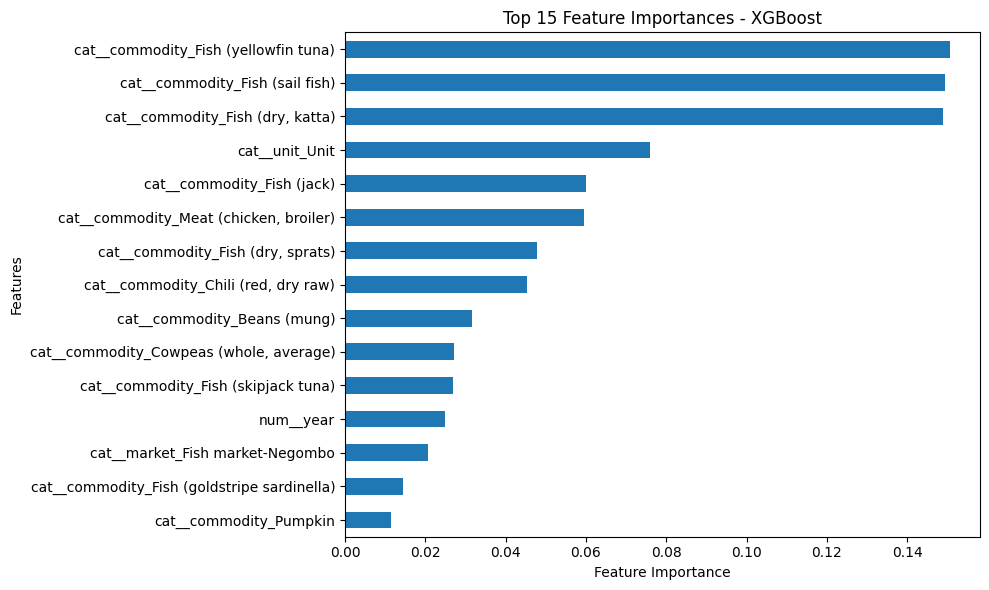

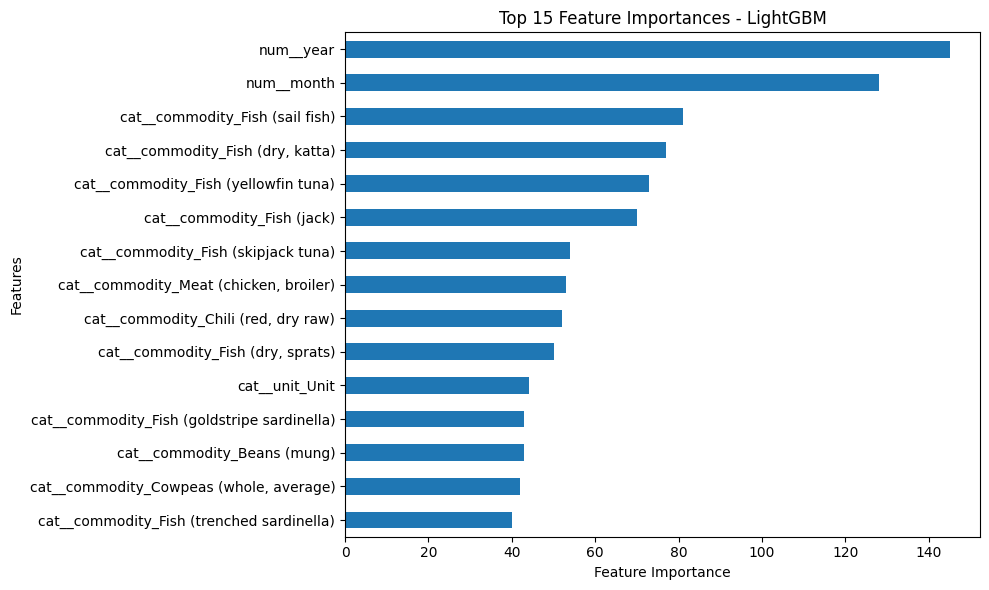

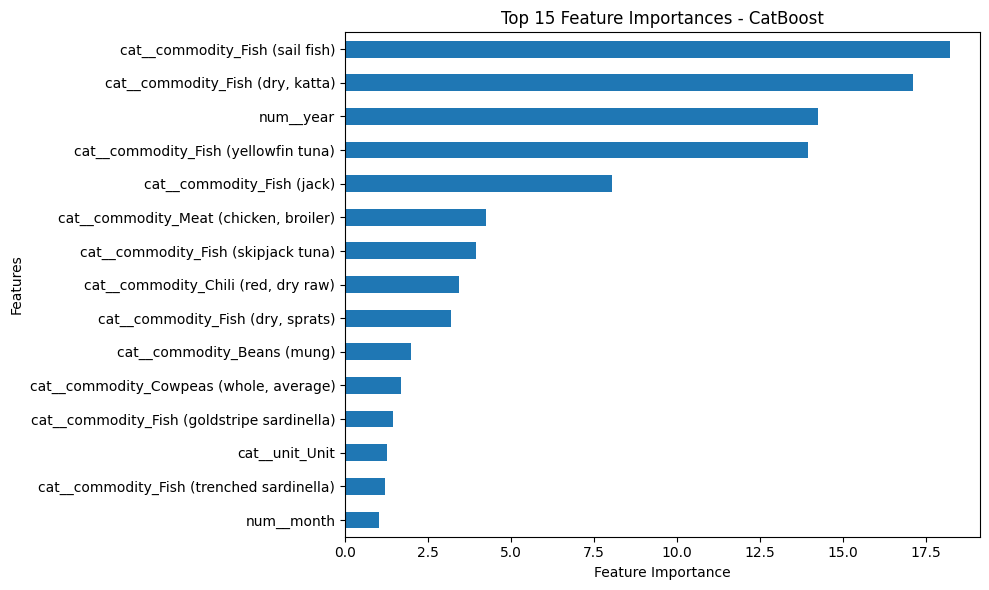

In [170]:
import matplotlib.pyplot as plt
import pandas as pd

feature_names = tuning_preprocessor.get_feature_names_out()

boosting_models = {
    'XGBoost': tuned_xgb,
    'LightGBM': tuned_lgbm,
    'CatBoost': tuned_cat
}

for model_name, model in boosting_models.items():

    importance = pd.Series(
        model.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    importance.sort_values().plot(kind='barh')

    plt.title(f'Top 15 Feature Importances - {model_name}')
    plt.xlabel('Feature Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

In [171]:
# Retrain tuned boosting models on all pre-2025 data
final_xgb = XGBRegressor(**xgb_search.best_params_, random_state=42)
final_lgbm = LGBMRegressor(**lgbm_search.best_params_, random_state=42, verbosity=-1)
final_cat = CatBoostRegressor(
    **cat_search.best_params_,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)

final_xgb.fit(X_train_processed, y_train)
final_lgbm.fit(X_train_processed, y_train)
final_cat.fit(X_train_processed, y_train)

# Generate 2025 predictions
final_predictions = {
    'Random Forest': rf_model.predict(X_test_processed),
    'XGBoost': final_xgb.predict(X_test_processed),
    'LightGBM': final_lgbm.predict(X_test_processed),
    'CatBoost': final_cat.predict(X_test_processed),
    'Stacking': stacking_predictions,
    'Hybrid RF + ANN': hybrid_predictions
}

# Calculate evaluation metrics
final_results = []

for name, predictions in final_predictions.items():
    final_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(final_results)
final_comparison = final_comparison.sort_values('MAE').reset_index(drop=True)

final_comparison.round(4)

,Model,MAE,RMSE,R2
0,Stacking,120.4602,174.0408,0.9290
1,XGBoost,124.3591,180.6740,0.9235
2,CatBoost,125.6818,181.6840,0.9226
3,LightGBM,126.9739,177.3770,0.9262
4,Random Forest,134.5089,202.1905,0.9041
5,Hybrid RF + ANN,142.5718,214.4527,0.8922


### Final Model Evaluation

The Stacking Ensemble achieved the best overall performance, with an MAE of 120.46 LKR, an RMSE of 174.04 LKR, and an R² score of 0.9290 on the 2025 test dataset.

XGBoost achieved the second-lowest MAE, while LightGBM achieved the second-highest R² score. The Random Forest model provided a reasonable baseline, whereas the Hybrid RF + ANN model did not improve prediction performance.

Based on the evaluation results, Stacking was selected as the best-performing model.

Note: The Stacking and Hybrid models used base models trained through 2023, while the standalone models were trained through 2024. This difference in training periods should be considered when interpreting the comparison.

### Save All Trained Models

Save all evaluated models (Random Forest, XGBoost, LightGBM, CatBoost, Stacking Ensemble, and Hybrid RF + ANN) along with their preprocessors using `joblib`.

In [172]:
import joblib
import os

In [173]:
os.makedirs("../models", exist_ok=True)

In [174]:
stacking_base_models = []
stacking_train_predictions = []

for name, model in base_models:
    model_copy = clone(model)
    model_copy.fit(X_tune_train_processed, y_tune_train)

    stacking_base_models.append((name, model_copy))
    stacking_train_predictions.append(
        model_copy.predict(X_validation_processed)
    )

stacking_train_features = np.column_stack(stacking_train_predictions)

In [175]:
meta_model = LinearRegression()
meta_model.fit(stacking_train_features, y_validation)

LinearRegression()

In [176]:
# Save standalone models (trained on 2004-2024) and their preprocessor
joblib.dump(rf_model, "../models/random_forest_model.pkl", compress=3)
joblib.dump(final_xgb, "../models/xgboost_model.pkl", compress=3)
joblib.dump(final_lgbm, "../models/lightgbm_model.pkl", compress=3)
joblib.dump(final_cat, "../models/catboost_model.pkl", compress=3)
joblib.dump(preprocessor, "../models/preprocessor.pkl", compress=3)

# Save Stacking Ensemble components and preprocessor
joblib.dump(stacking_base_models, "../models/stacking_base_models.pkl", compress=3)
joblib.dump(meta_model, "../models/stacking_meta_model.pkl", compress=3)
joblib.dump(tuning_preprocessor, "../models/stacking_preprocessor.pkl", compress=3)

# Save Hybrid RF + ANN components and bundle (uses stacking_preprocessor.pkl)
joblib.dump(tuned_rf, "../models/tuned_rf_model.pkl", compress=3)
joblib.dump(ann_model, "../models/ann_model.pkl", compress=3)
hybrid_model_bundle = {
    "rf_model": tuned_rf,
    "ann_model": ann_model,
    "rf_weight": best_rf_weight,
    "ann_weight": best_ann_weight
}
joblib.dump(hybrid_model_bundle, "../models/hybrid_rf_ann_model.pkl", compress=3)

print("Saved files:", sorted(os.listdir("../models")))

Saved files: ['ann_model.pkl', 'catboost_model.pkl', 'hybrid_rf_ann_model.pkl', 'lightgbm_model.pkl', 'preprocessor.pkl', 'random_forest_model.pkl', 'stacking_base_models.pkl', 'stacking_meta_model.pkl', 'stacking_preprocessor.pkl', 'tuned_rf_model.pkl', 'xgboost_model.pkl']


In [177]:
import sklearn
print(sklearn.__version__)

1.6.1
